# Benchmarking A* on 8-Connected Grids

## Experimental Setup

**Карты.** Для тестирования выбраны три карты из коллекции MovingAI с визуально различной топологией:

- `16room_003.map` — комнаты с узкими проходами; важна аккуратная обработка коридоров и поворотов.
- `battleground.map` — игровая карта Warcraft 3 с открытыми зонами и локальными препятствиями; на ней хорошо видны различия эвристик на длинных маршрутах.
- `maze512-1-0.map` — сложный лабиринт с коридорами шириной 1; почти все перемещения вынужденно ортогональные, поэтому эвристики ведут себя иначе, чем на открытых картах.

**Задания.** Для каждой карты из соответствующего файла `.scen` равномерно по всем бакетам сложности выбирается 120 заданий (от коротких до длинных маршрутов). Задания с `opt_len <= 0` отбрасываются, после чего индексы выбираются через `np.linspace` по всему отфильтрованному списку. В файлах MovingAI используется координата `x` для столбца и `y` для строки, поэтому при загрузке выполняется преобразование `i = y`, `j = x`.

**Эвристики.** Сравниваются четыре эвристики: Euclidean, Octile (Diagonal), Chebyshev и Manhattan. Первые три допустимы для 8-связного грида без срезания углов, а Manhattan для такого графа недопустима, поэтому для неё ожидаемы меньшая доля оптимальных путей и рост Suboptimality %.

**Алгоритм.** Во всех запусках используется A* на 8-связном гриде без срезания углов. Диагональный переход разрешён только тогда, когда свободны и целевая диагональная клетка, и обе смежные ортогональные клетки. В очереди с приоритетом применяется tie-breaking по большему `g` при практически равных значениях `f`.

**Метрики.** Для каждого запуска отслеживаются:

- **Optimal %** — процент заданий, для которых найденная длина совпала с эталонной `opt_len`;
- **Suboptimality %** — отношение найденной длины к эталонной: `length / opt_len * 100`;
- **expansions / steps** — число раскрытых вершин;
- **time, мс** — время работы алгоритма, измеренное через `time.perf_counter()`.

Таблицы и графики ниже позволяют сравнивать эвристики как по средним значениям, так и по разбросу метрик между заданиями разной сложности.

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math
import time
import heapq
import PIL

In [7]:
class Map:
    def __init__(self, cells):
        self.cells = cells
        self.h, self.w = cells.shape

    def get_neighbors(self, i, j):
        out = []
        for di, dj in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
            ni, nj = i + di, j + dj
            if 0 <= ni < self.h and 0 <= nj < self.w and self.cells[ni, nj] == 0:
                out.append((ni, nj))
        for di, dj in [(-1, -1), (-1, 1), (1, -1), (1, 1)]:
            ni, nj = i + di, j + dj
            if not (0 <= ni < self.h and 0 <= nj < self.w):
                continue
            if self.cells[ni, nj] != 0:
                continue
            if not (0 <= i + di < self.h and 0 <= j < self.w):
                continue
            if not (0 <= i < self.h and 0 <= j + dj < self.w):
                continue
            if self.cells[i + di, j] != 0 or self.cells[i, j + dj] != 0:
                continue
            out.append((ni, nj))
        return out


def load_map(path):
    with open(path) as f:
        lines = f.read().splitlines()
    h = int(lines[1].split()[1])
    w = int(lines[2].split()[1])
    cells = np.ones((h, w), dtype=np.uint8)
    for i, row in enumerate(lines[4:4 + h]):
        for j, ch in enumerate(row[:w]):
            if ch == "." or ch == "G":
                cells[i, j] = 0
    return Map(cells)


def load_scen(path, count=120):
    with open(path) as f:
        lines = f.read().splitlines()[1:]
    tasks = []
    for line in lines:
        parts = line.split()
        if len(parts) < 9:
            continue
        sx, sy = int(parts[4]), int(parts[5])
        gx, gy = int(parts[6]), int(parts[7])
        opt = float(parts[8])
        if opt > 0:
            tasks.append((sy, sx, gy, gx, opt))
    idx = np.linspace(0, len(tasks) - 1, count).astype(int)
    return [tasks[k] for k in idx]


def cost(i1, j1, i2, j2):
    if abs(i1 - i2) + abs(j1 - j2) == 1:
        return 1.0
    return math.sqrt(2)

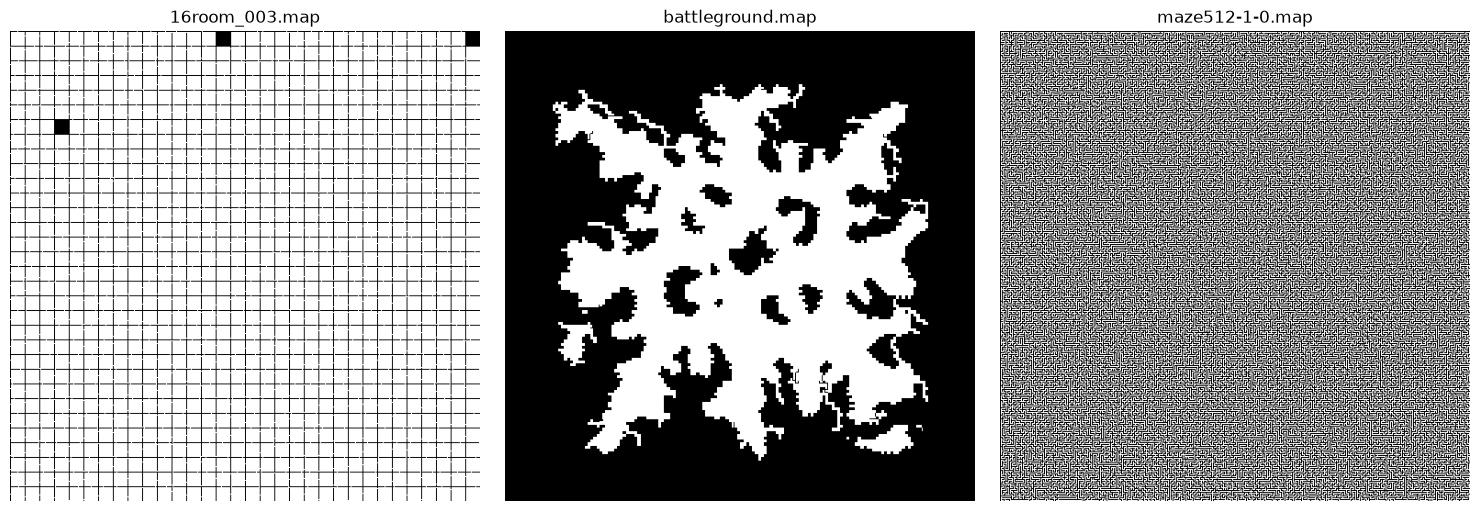

In [8]:
names = ["16room_003.map", "battleground.map", "maze512-1-0.map"]
maps = [load_map("data/" + n) for n in names]
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
for ax, m, n in zip(axs, maps, names):
    ax.imshow(m.cells, cmap="gray_r", vmin=0, vmax=1)
    ax.set_title(n)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [9]:
def euclidean(i1, j1, i2, j2):
    return math.hypot(i1 - i2, j1 - j2)


def octile(i1, j1, i2, j2):
    dx = abs(i1 - i2)
    dy = abs(j1 - j2)
    return (dx + dy) + (math.sqrt(2) - 2) * min(dx, dy)


def chebyshev(i1, j1, i2, j2):
    return max(abs(i1 - i2), abs(j1 - j2))


def manhattan(i1, j1, i2, j2):
    return abs(i1 - i2) + abs(j1 - j2)

In [10]:
class Node:
    def __init__(self, i, j, g, h, parent=None):
        self.i = i
        self.j = j
        self.g = g
        self.h = h
        self.f = g + h
        self.parent = parent

    def __lt__(self, other):
        if abs(self.f - other.f) < 1e-6:
            return self.g > other.g
        return self.f < other.f


class SearchTree:
    def __init__(self):
        self.q = []
        self.closed = {}
        self.best = {}
        self.n = 0

    def push(self, node):
        key = (node.i, node.j)
        if key in self.closed:
            return
        if key in self.best and self.best[key] <= node.g + 1e-9:
            return
        self.best[key] = node.g
        self.n += 1
        heapq.heappush(self.q, (node, self.n))

    def pop(self):
        while self.q:
            node, _ = heapq.heappop(self.q)
            key = (node.i, node.j)
            if key in self.closed:
                continue
            if key in self.best and node.g > self.best[key] + 1e-9:
                continue
            self.closed[key] = node
            return node
        return None


def astar(grid, si, sj, gi, gj, h_func):
    t0 = time.perf_counter()
    tree = SearchTree()
    tree.push(Node(si, sj, 0.0, h_func(si, sj, gi, gj)))
    found = False
    length = float("inf")
    expansions = 0
    while True:
        node = tree.pop()
        if node is None:
            break
        expansions += 1
        if node.i == gi and node.j == gj:
            found = True
            length = node.g
            break
        for ni, nj in grid.get_neighbors(node.i, node.j):
            g = node.g + cost(node.i, node.j, ni, nj)
            tree.push(Node(ni, nj, g, h_func(ni, nj, gi, gj), node))
    runtime_ms = (time.perf_counter() - t0) * 1000
    return found, length, expansions, runtime_ms

In [11]:
hs = [("Octile", octile), ("Euclidean", euclidean), ("Chebyshev", chebyshev), ("Manhattan", manhattan)]
rs = []
for name, m in zip(names, maps):
    ts = load_scen("data/" + name + ".scen", 120)
    for hn, h in hs:
        for k, (si, sj, gi, gj, opt) in enumerate(ts):
            found, ln, ex, tm = astar(m, si, sj, gi, gj, h)
            rs.append({
                "map": name,
                "task_id": k,
                "bucket": k // 10 + 1,
                "heuristic": hn,
                "opt_len": opt,
                "len": ln,
                "optimal": abs(ln - opt) <= 1e-4,
                "subopt_pct": (ln / opt) * 100,
                "expansions": ex,
                "time_ms": tm,
            })
df = pd.DataFrame(rs)
print(df.shape)

(1440, 10)


In [12]:
d = df.copy()
d.loc[~np.isfinite(d["subopt_pct"]), "subopt_pct"] = np.nan
g = d.groupby(["map", "heuristic"])
t = pd.DataFrame({
    ("Optimal (%)", "mean"): g["optimal"].mean() * 100,
    ("Suboptimality (%)", "mean"): g["subopt_pct"].mean(),
    ("Suboptimality (%)", "std"): g["subopt_pct"].std(),
    ("Expansions", "mean"): g["expansions"].mean(),
    ("Expansions", "std"): g["expansions"].std(),
    ("Expansions", "median"): g["expansions"].median(),
    ("Expansions", "IQR"): g["expansions"].agg(lambda s: s.quantile(0.75) - s.quantile(0.25)),
    ("Time (ms)", "mean"): g["time_ms"].mean(),
    ("Time (ms)", "std"): g["time_ms"].std(),
    ("Time (ms)", "median"): g["time_ms"].median(),
    ("Time (ms)", "IQR"): g["time_ms"].agg(lambda s: s.quantile(0.75) - s.quantile(0.25)),
})
t = t.round(2)
t.style.format("{:.2f}").set_caption("A* benchmark summary")

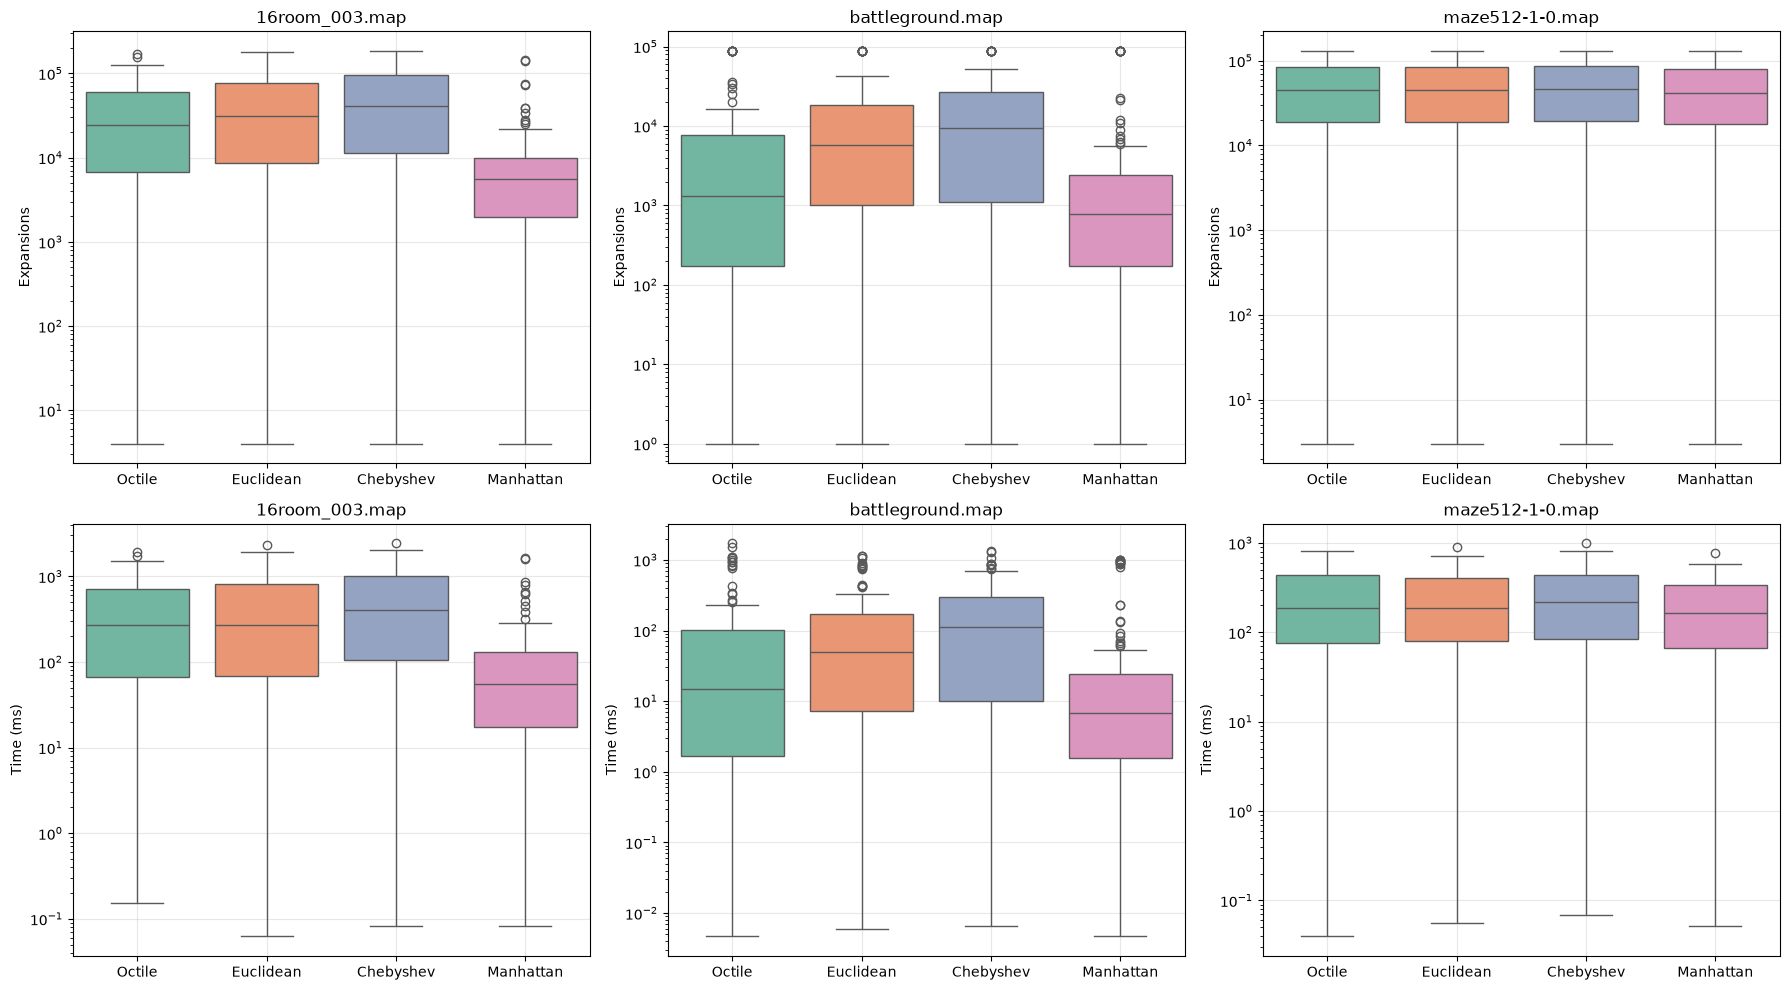

In [13]:
order = ["Octile", "Euclidean", "Chebyshev", "Manhattan"]
fig, axs = plt.subplots(2, 3, figsize=(18, 10))
for c, name in enumerate(names):
    d = df[df["map"] == name]
    sns.boxplot(data=d, x="heuristic", y="expansions", order=order, hue="heuristic", legend=False, palette="Set2", ax=axs[0, c])
    axs[0, c].set_title(name)
    axs[0, c].set_xlabel("")
    axs[0, c].set_ylabel("Expansions")
    axs[0, c].set_yscale("log")
    axs[0, c].grid(True, alpha=0.3)
    sns.boxplot(data=d, x="heuristic", y="time_ms", order=order, hue="heuristic", legend=False, palette="Set2", ax=axs[1, c])
    axs[1, c].set_title(name)
    axs[1, c].set_xlabel("")
    axs[1, c].set_ylabel("Time (ms)")
    axs[1, c].set_yscale("log")
    axs[1, c].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

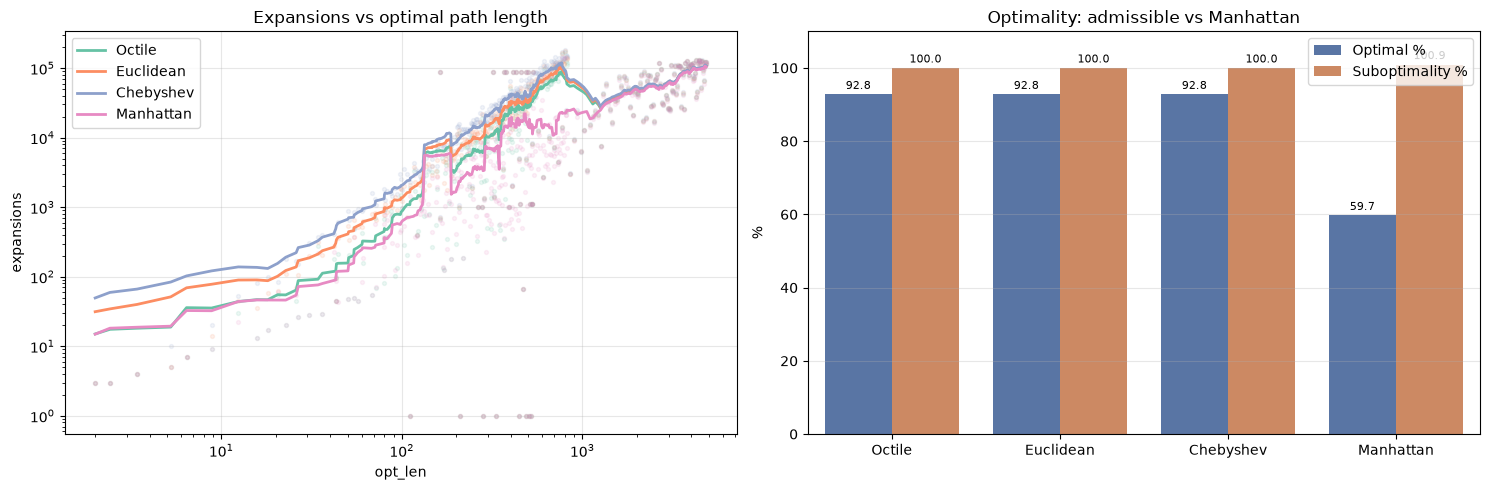

In [14]:
order = ["Octile", "Euclidean", "Chebyshev", "Manhattan"]
cols = dict(zip(order, sns.color_palette("Set2", 4)))
fig, axs = plt.subplots(1, 2, figsize=(15, 5))
for hn in order:
    d = df[df["heuristic"] == hn].sort_values("opt_len")
    axs[0].scatter(d["opt_len"], d["expansions"], s=8, alpha=0.12, color=cols[hn])
    sm = d["expansions"].rolling(21, center=True, min_periods=5).mean()
    axs[0].plot(d["opt_len"], sm, lw=2, color=cols[hn], label=hn)
axs[0].set_xscale("log")
axs[0].set_yscale("log")
axs[0].set_xlabel("opt_len")
axs[0].set_ylabel("expansions")
axs[0].set_title("Expansions vs optimal path length")
axs[0].legend()
axs[0].grid(True, alpha=0.3)
d = df.copy()
d.loc[~np.isfinite(d["subopt_pct"]), "subopt_pct"] = np.nan
g = d.groupby("heuristic")
s = pd.DataFrame(index=order)
s["Optimal %"] = g["optimal"].mean().reindex(order) * 100
s["Suboptimality %"] = g["subopt_pct"].mean().reindex(order)
s = s.rename_axis("heuristic").reset_index()
m = s.melt(id_vars="heuristic", var_name="metric", value_name="value")
sns.barplot(data=m, x="heuristic", y="value", hue="metric", order=order, palette=["#4c72b0", "#dd8452"], ax=axs[1])
axs[1].set_xlabel("")
axs[1].set_ylabel("%")
axs[1].set_ylim(0, 110)
axs[1].set_title("Optimality: admissible vs Manhattan")
axs[1].legend(title="")
axs[1].grid(True, axis="y", alpha=0.3)
for c in axs[1].containers:
    axs[1].bar_label(c, fmt="%.1f", fontsize=8, padding=2)
plt.tight_layout()
plt.show()

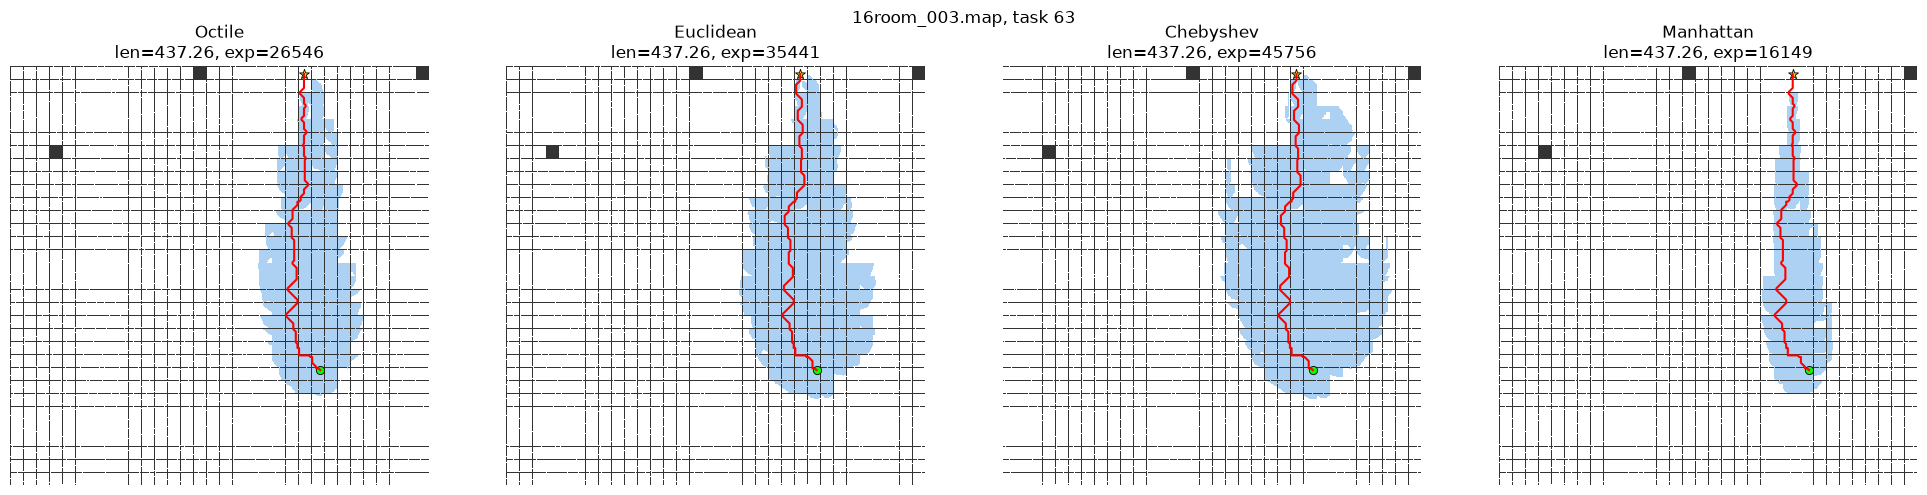

In [15]:
def trace(m, si, sj, gi, gj, h):
    tr = SearchTree()
    tr.push(Node(si, sj, 0.0, h(si, sj, gi, gj)))
    while True:
        nd = tr.pop()
        if nd is None:
            return False, [], set(tr.closed)
        if nd.i == gi and nd.j == gj:
            p = []
            while nd is not None:
                p.append((nd.i, nd.j))
                nd = nd.parent
            return True, p[::-1], set(tr.closed)
        for ni, nj in m.get_neighbors(nd.i, nd.j):
            gg = nd.g + cost(nd.i, nd.j, ni, nj)
            tr.push(Node(ni, nj, gg, h(ni, nj, gi, gj), nd))


name = "16room_003.map"
m = maps[names.index(name)]
d = df[(df["map"] == name) & df["optimal"]]
p = d.pivot(index="task_id", columns="heuristic", values="expansions").dropna()
tid = int((p.max(axis=1) - p.min(axis=1)).idxmax())
si, sj, gi, gj, opt = load_scen("data/" + name + ".scen", 120)[tid]
fig, axs = plt.subplots(1, 4, figsize=(20, 5))
for ax, (hn, h) in zip(axs, hs):
    found, pth, exp = trace(m, si, sj, gi, gj, h)
    img = np.ones((m.h, m.w, 3))
    img[m.cells == 1] = 0.2
    if exp:
        ei = np.array([v[0] for v in exp])
        ej = np.array([v[1] for v in exp])
        img[ei, ej] = [0.68, 0.82, 0.95]
    if pth:
        pi = np.array([v[0] for v in pth])
        pj = np.array([v[1] for v in pth])
        img[pi, pj] = [0.9, 0.1, 0.1]
    ax.imshow(img, interpolation="nearest")
    if pth:
        ax.plot([v[1] for v in pth], [v[0] for v in pth], c="red", lw=1.5)
    ax.scatter([sj], [si], c="lime", s=35, marker="o", edgecolors="black", linewidths=0.6)
    ax.scatter([gj], [gi], c="gold", s=55, marker="*", edgecolors="black", linewidths=0.6)
    plen = sum(cost(pth[k][0], pth[k][1], pth[k + 1][0], pth[k + 1][1]) for k in range(len(pth) - 1)) if pth else float("inf")
    ax.set_title(f"{hn}\nlen={plen:.2f}, exp={len(exp)}")
    ax.axis("off")
fig.suptitle(f"{name}, task {tid}")
plt.tight_layout()
plt.show()

# Анализ результатов и выводы

Сначала о таблицах. Задания в выборке разные по сложности, поэтому распределения метрик скошены: несколько длинных задач сильно тянут среднее вверх. Поэтому вместе с `mean` стоит смотреть медиану и IQR: медиана показывает типичный запуск, IQR — разброс центральной половины, а `std` чувствителен к выбросам. На boxplot видно, что даже внутри одной карты число раскрытий меняется на порядки.

Допустимые эвристики. Octile, Euclidean и Chebyshev не переоценивают стоимость пути, поэтому на корректных заданиях дают оптимальный маршрут. На `16room_003` и `maze512-1-0` это 100% оптимальных путей. На `battleground` в таблице 78.33%, но причина не в эвристиках: по заданному правилу чтения карты `S`, `W` и `T` считаются препятствиями, и у части сценариев старт или цель попадает в такую клетку. Среди решённых заданий все три эвристики оптимальны.

По числу раскрытий они идут в порядке `Octile <= Euclidean <= Chebyshev`. Для одной и той же пары клеток `h_octile >= h_euclidean >= h_chebyshev`; чем ближе допустимая оценка к `h*`, тем раньше A* отбрасывает неперспективные ветви. На `16room_003` это примерно 37.8, 46.1 и 55.6 тыс. раскрытий в среднем. Время ведёт себя менее стабильно из-за накладных расходов Python, но медианы и IQR показывают ту же тенденцию.

Manhattan. На диагональном шаге `dx = dy = 1` она даёт `2` вместо `sqrt(2)`, то есть переоценивает стоимость примерно на 41%. Из-за этого теряется гарантия оптимальности: на `16room_003` оптимальны только 21.67% путей, средняя субоптимальность 102.05%; на `battleground` — 57.5%. Зато поиск становится направленнее и работает быстрее: на `16room_003` среднее число раскрытий падает с 37.8 до 10.9 тыс., время — примерно с 537 до 119 мс.

Топология. На battleground с открытыми зонами и в комнатах `16room_003` различия между эвристиками проявляются сильнее. В `maze512-1-0` коридоры шириной 1 заставляют идти в основном ортогонально, поэтому эвристики дают близкие оценки: у Octile, Euclidean и Chebyshev около 53.6–54.9 тыс. раскрытий. Manhattan в лабиринте тоже находит оптимальные пути во всех заданиях и раскрывает около 51.6 тыс. вершин, так как диагональные переоценки там почти не возникают.

Вывод. Если нужна гарантия кратчайшего пути, лучше всего выглядит Octile: она оптимальна и стабильно раскрывает меньше вершин, чем Euclidean и Chebyshev. Manhattan уместна, когда важнее скорость, а небольшая потеря качества пути допустима. На лабиринте разница между эвристиками заметно меньше, чем на открытых картах.